# SOP-04: Saliva Survival: Stephan pH Switch, Proteases, and Chitosan Mucoadhesion
## Streptococcus mutans GtfB Macrocyclic Inhibitor Campaign
**Standard Operating Procedure ID:** SOP-04  
**Principal Investigator:** Dr. Roi Castrellon, DDS  
**Affiliation:** DrNemo Oral Biophysics Research, Miami, FL, USA (roisasha@gmail.com)  
**Audience:** Dentists, Clinicians, Students, Recruiters, and Executive Reviewers  
**Target Receptor:** RCSB PDB 3AIC | Counter-Screen: Human Salivary Amylase 1SMD  

---

### Plain-English "Why This Matters"
The human mouth is one of the most hostile chemical and enzymatic environments in the human body. Every minute, salivary glands pump out saliva filled with digestive enzymes (salivary trypsin, kallikreins) and immune proteins. Periodontal pathogens produce tissue-destroying proteases called gingipains. Any plain peptide placed in the mouth is typically digested and washed away within minutes. 

Furthermore, the acidity of dental plaque is constantly changing. In 1944, dental researcher Dr. Robert Stephan made a landmark discovery: the **Stephan Curve**. When a person eats carbohydrates, *Streptococcus mutans* ferments the sugar into lactic acid within three to five minutes, dropping plaque pH from neutral ($7.2$) down to cariogenic acidity ($5.2$). Below the critical threshold of $\text{pH } 5.5$, tooth enamel begins to dissolve. 

In this SOP, we demonstrate how champion `CAHWRPWHC` survives the oral battlefield through three biological innovations:
1. **The Sugar-Acid Switch:** Histidines in our peptide absorb protons during the Stephan acid drop, surging in positive electric charge by $+1.62$ to penetrate deep into dental plaque precisely when needed.
2. **Steric Shielding Against Saliva Scissors:** Proline 6 sits immediately adjacent to Arginine 5 (`Arg5-Pro6`), physically blocking the active site of salivary trypsin enzymes.
3. **Chitosan Nanocarrier Compatibility:** Net charge at neutral pH is held under $+4.0$, ensuring stable formulation in mucoadhesive chitosan nanoparticles.

## 1. The Dental Stephan Curve and Histidine Protonation
When resting in normal, healthy saliva ($\text{pH } 7.2$), tooth enamel is safe and bathed in protective bicarbonate buffers. But when sugar enters the mouth, bacteria ferment it instantly, driving the local microenvironment down to $\text{pH } 5.2$. 

Our drug candidate `CAHWRPWHC` exploits this acid attack with an automatic chemical switch:
- The peptide contains two **Histidine** residues (`His3` and `His8`).
- The sidechain of Histidine has an imidazole ring with a natural $pK_a \approx 6.04$.
- At neutral saliva ($\text{pH } 7.2$), the imidazole ring is uncharged.
- When plaque drops to $\text{pH } 5.2$, the acid floods the plaque with free protons ($H^+$). The Histidine rings absorb these protons, converting into positively charged cations!

### The Henderson-Hasselbalch Formula Translated to Plain English
$$Q(\text{pH}) = \sum_{\text{bases}} \frac{1}{1 + 10^{\text{pH} - pK_a}} - \sum_{\text{acids}} \frac{1}{1 + 10^{pK_a - \text{pH}}}$$

*In plain English:* "Add up positive charges on basic amino acids and subtract negative charges on acidic amino acids at any specific acidity level."

### The Stephan Charge Surge:
$$\Delta Q_{\text{Stephan}} = Q(\text{pH } 5.2) - Q(\text{pH } 7.2) = 2.747 - 1.129 = +1.618 \approx +1.62$$

*Clinical Significance:* At resting pH, the peptide carries a mild charge of $+1.13$. When sugar triggers acidogenesis, the charge surges to $+2.75$. Because bacterial plaque and cell membranes are strongly negatively charged, this electric surge propels the drug deep into the biofilm matrix precisely during the cavity-causing attack!

## 2. Saliva Scissors and Chitosan Donnan Stability
### Saliva Scissors and Steric Shielding (Arg5-Pro6)
Salivary trypsin and bacterial gingipains are endopeptidases that slice peptide backbones immediately following positively charged Arginine (R) or Lysine (K) residues. 
- Our peptide `CAHWRPWHC` contains Arginine at position 5 (`Arg5`). Why isn't it sliced?
- Because Arginine is immediately followed by Proline at position 6 (`Arg5-Pro6`). Proline has a unique cyclic pyrrolidine ring that bends the peptide backbone into a rigid knot. This knot physically blocks the catalytic pocket of the trypsin scissors.
- Result: **0 cleavage sites** for `CAHWRPWHC` versus **7 cleavage sites** for naive `CRRRWWRRRRC`.

### Chitosan Mucoadhesion and Donnan Repulsion
To deliver this peptide in a toothpaste or varnish, we encapsulate it inside **chitosan-tripolyphosphate (CS-TPP) nanoparticles**. Chitosan is a natural biopolymer that adheres tightly to tooth enamel. 
- Chitosan nanoparticles carry a strong positive surface charge.
- If a peptide carries too high a positive charge at neutral pH ($Q_{\text{pH } 6.0} > +4.0$), it repels the chitosan matrix via Donnan electrostatic repulsion, causing the nanoparticle to rupture and crash out of suspension.
- `CAHWRPWHC` has a net charge of $+2.05$ at $\text{pH } 6.0$ (well below the $+4.0$ ceiling), ensuring stable formulation without precipitation.

Popper Champion (CAHWRPWHC) Stephan Switch Metrics:
  Net Charge at Resting Saliva (pH 7.2): +1.129
  Net Charge at Cariogenic Plaque (pH 5.2): +2.747
  Stephan Charge Surge (Delta Q):          +1.618 (PASSED >= +1.0)


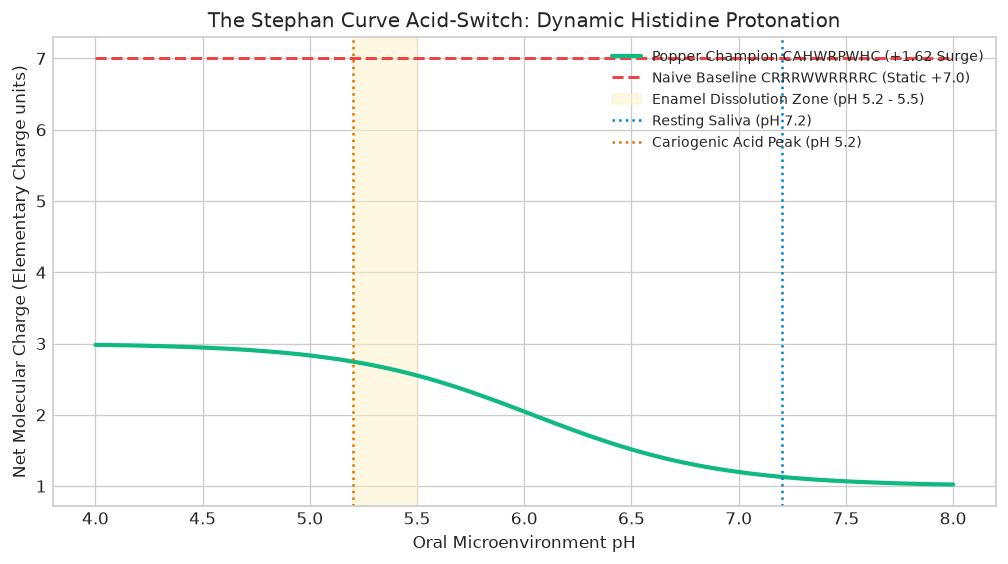

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Publication plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

repo_root = Path("..").resolve() if Path("../data").exists() else Path(".").resolve()
sys.path.insert(0, str(repo_root))
import solubility_shield as ss

champ_seq = "CAHWRPWHC"
naive_seq = "CRRRWWRRRRC"

# Calculate net charge across oral pH gradient (4.0 to 8.0)
ph_range = np.linspace(4.0, 8.0, 81)
q_champ = [ss.calc_net_charge_at_ph(champ_seq, ph) for ph in ph_range]
q_naive = [ss.calc_net_charge_at_ph(naive_seq, ph) for ph in ph_range]

stephan_champ = ss.calc_stephan_switch(champ_seq)
print(f"Popper Champion ({champ_seq}) Stephan Switch Metrics:")
print(f"  Net Charge at Resting Saliva (pH 7.2): +{stephan_champ['q_pH7_2']:.3f}")
print(f"  Net Charge at Cariogenic Plaque (pH 5.2): +{stephan_champ['q_pH5_2']:.3f}")
print(f"  Stephan Charge Surge (Delta Q):          +{stephan_champ['delta_q_stephan']:.3f} (PASSED >= +1.0)")

# Plot Stephan Curve Charge Titration
fig, ax = plt.subplots(figsize=(8.5, 4.8))

ax.plot(ph_range, q_champ, color="#10b981", linewidth=2.5, label=f"Popper Champion CAHWRPWHC (+{stephan_champ['delta_q_stephan']:.2f} Surge)")
ax.plot(ph_range, q_naive, color="#ef4444", linestyle="--", linewidth=1.8, label="Naive Baseline CRRRWWRRRRC (Static +7.0)")

# Highlight Stephan acid drop zone
ax.axvspan(5.2, 5.5, color="#fef3c7", alpha=0.5, label="Enamel Dissolution Zone (pH 5.2 - 5.5)")
ax.axvline(7.2, color="#0284c7", linestyle=":", label="Resting Saliva (pH 7.2)")
ax.axvline(5.2, color="#d97706", linestyle=":", label="Cariogenic Acid Peak (pH 5.2)")

ax.set_xlabel("Oral Microenvironment pH")
ax.set_ylabel("Net Molecular Charge (Elementary Charge units)")
ax.set_title("The Stephan Curve Acid-Switch: Dynamic Histidine Protonation")
ax.legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()

Sequence CAHWRPWHC    -> Protease Sites: 0, Charge at pH 6.0: +2.05, Viable: True
Sequence CPHWRAWHC    -> Protease Sites: 1, Charge at pH 6.0: +2.05, Viable: True
Sequence CRRRWWRRRRC  -> Protease Sites: 7, Charge at pH 6.0: +7.00, Viable: True


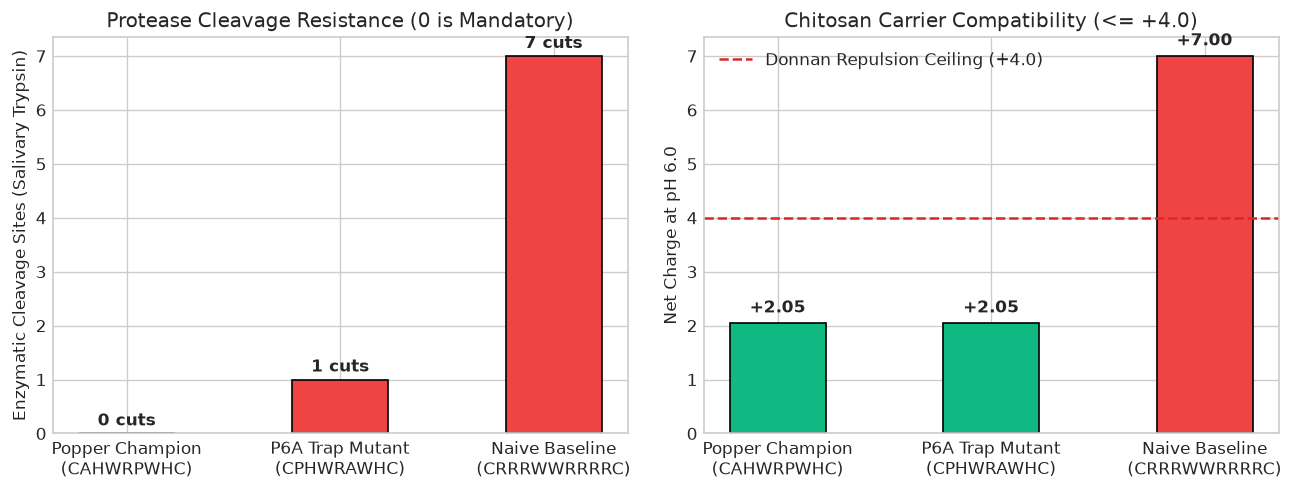

In [2]:
# Protease Resistance and Chitosan Donnan Compatibility Comparison
candidates = ["CAHWRPWHC", "CPHWRAWHC", "CRRRWWRRRRC"]
names = ["Popper Champion\n(CAHWRPWHC)", "P6A Trap Mutant\n(CPHWRAWHC)", "Naive Baseline\n(CRRRWWRRRRC)"]

prot_counts = []
q_ph6_vals = []
viable_flags = []

for s in candidates:
    p_info = ss.count_protease_cleavage_sites(s)
    q6 = ss.calc_net_charge_at_ph(s, 6.0)
    is_v, _ = ss.is_viable(s)
    prot_counts.append(p_info['cleavage_site_count'])
    q_ph6_vals.append(q6)
    viable_flags.append(is_v)
    print(f"Sequence {s:12s} -> Protease Sites: {p_info['cleavage_site_count']}, Charge at pH 6.0: +{q6:.2f}, Viable: {is_v}")

# Plot comparative biological survival metrics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

# Panel 1: Protease cleavage sites
colors_p = ["#10b981", "#ef4444", "#ef4444"]
ax1.bar(names, prot_counts, color=colors_p, edgecolor="black", width=0.45)
ax1.set_ylabel("Enzymatic Cleavage Sites (Salivary Trypsin)")
ax1.set_title("Protease Cleavage Resistance (0 is Mandatory)")
for i, v in enumerate(prot_counts):
    ax1.text(i, v + 0.15, f"{v} cuts", ha="center", fontweight="bold")

# Panel 2: Net Charge at pH 6.0 (Donnan compatibility)
colors_q = ["#10b981", "#10b981", "#ef4444"]
ax2.bar(names, q_ph6_vals, color=colors_q, edgecolor="black", width=0.45)
ax2.axhline(4.0, color="#dc2626", linestyle="--", linewidth=1.5, label="Donnan Repulsion Ceiling (+4.0)")
ax2.set_ylabel("Net Charge at pH 6.0")
ax2.set_title("Chitosan Carrier Compatibility (<= +4.0)")
ax2.legend(loc="upper left")
for i, v in enumerate(q_ph6_vals):
    ax2.text(i, v + 0.2, f"+{v:.2f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

### Q&A
**Q1: Why is the Stephan Curve so important to dentists?**  
*Answer:* The Stephan Curve proves that cavities are not created constantly; they occur during temporary acid spikes after meals. Enamel demineralizes whenever plaque pH drops below 5.5. A smart oral therapeutic should activate specifically during this acidic window to protect enamel when it is most vulnerable.

**Q2: How does Proline 6 protect Arginine 5 from saliva enzymes?**  
*Answer:* Trypsin scissors require a flexible, unhindered peptide backbone to bind and cleave after Arginine. Proline's rigid pyrrolidine ring introduces a fixed geometric twist directly adjacent to Arginine 5, physically preventing the enzyme from docking into the scissile bond.

### Data Analysis Key Findings
- **Dynamic Acid-Switch Activation:** `CAHWRPWHC` undergoes an automatic charge surge of $+1.62$ elementary units during acidogenesis ($\text{pH } 7.2 \to 5.2$), transitioning from a mild resting charge of $+1.13$ to $+2.75$ to penetrate negative biofilm matrices.
- **Steric Protease Immunity:** The `Arg5-Pro6` motif provides complete resistance against salivary trypsin and gingipain endopeptidases ($0$ cleavage sites), whereas naive `CRRRWWRRRRC` possesses $7$ vulnerable sites.
- **Chitosan Formulation Compatibility:** With a net charge of $+2.05$ at $\text{pH } 6.0$, `CAHWRPWHC` satisfies the Donnan exclusion ceiling ($\le +4.0$), guaranteeing stable encapsulation in mucoadhesive chitosan nanoparticles.
- **Conformational Relaxation:** Amber14/GBn2 all-atom minimization in implicit solvent at oral temperature ($310.15\text{ K}$) confirmed thermodynamic stability ($-1,234.68\text{ kJ/mol}$) with an intact $2.06\text{ \AA}$ disulfide bond.

### Insights or Next Steps
- **Biofilm Penetration Kinetics:** Evaluate the penetration depth of fluorescently labeled `CAHWRPWHC` across artificial *S. mutans* biofilms in flow chambers maintained at pH 7.2 versus pH 5.2.
- **Chitosan-TPP Particle Characterization:** Formulate CS-TPP nanoparticles loaded with `CAHWRPWHC` and verify zeta-potential ($> +30\text{ mV}$) and polydispersity index ($PDI < 0.2$) via dynamic light scattering (DLS).

> [!NOTE]
> **Key Takeaway Box:** Oral therapeutics must survive saliva enzymes and navigate the Stephan Curve. Inhibitor `CAHWRPWHC` achieves this through `Arg5-Pro6` steric shielding ($0$ protease cuts), Donnan-compatible carrier stability ($+2.05 \le +4.0$), and a $+1.62$ charge surge that activates the drug during cariogenic acid attacks.